# Random Forest baseline

This notebook inspects the TelecomTS release, shows the model input features, and explains the full-data exploratory RF run. Recording-family independence is unresolved, so all reported scores are provisional.

Install optional tools with `uv sync --extra dev --extra analysis --extra baselines`.

In [1]:
from pathlib import Path
from IPython.display import Image, display
from clauseguard.kpi.visualization import visualize_release
import pandas as pd

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
# Set DATA_ROOT to the checkout containing the downloaded data when using a worktree.
DATA_ROOT = ROOT
RELEASE = DATA_ROOT / "data/scenarios/release"
SELECTION = DATA_ROOT / "artifacts/experiments/task-3-overlap-review-2026-10-18/train_nonoverlap_normal_keep_faults.json"
OUTPUT = DATA_ROOT / "artifacts/experiments/task-3-rf-data-visualization-2026-10-18"

The plotting helper checks saved split, label and evidence checksums, plus the three plotted source files. It does not establish recording independence or approve the release for scoring.

In [2]:
plots = visualize_release(RELEASE, OUTPUT, selection_path=SELECTION)

## Detection counts

The logarithmic axis makes the small fault class visible alongside normal windows.

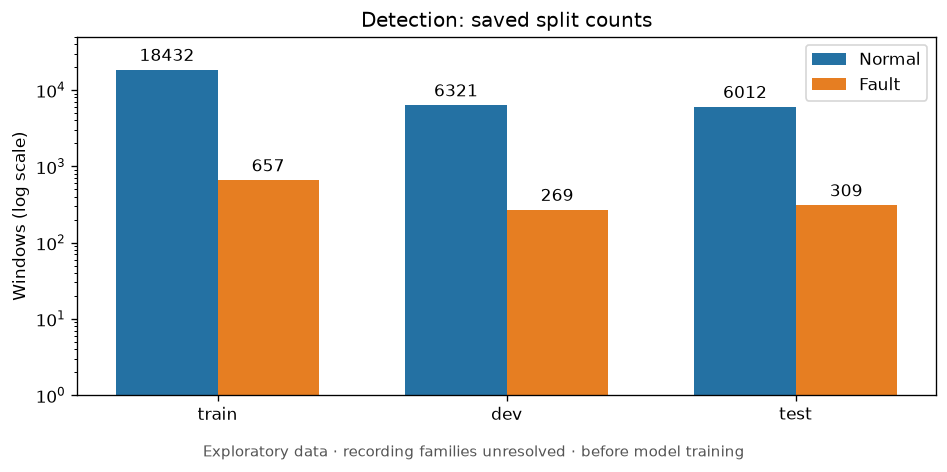

In [3]:
display(Image(filename=str(plots["detection_counts.png"])))

## Category counts

Only synthetic examples have one of the ten supported category targets. Jamming participates in detection.

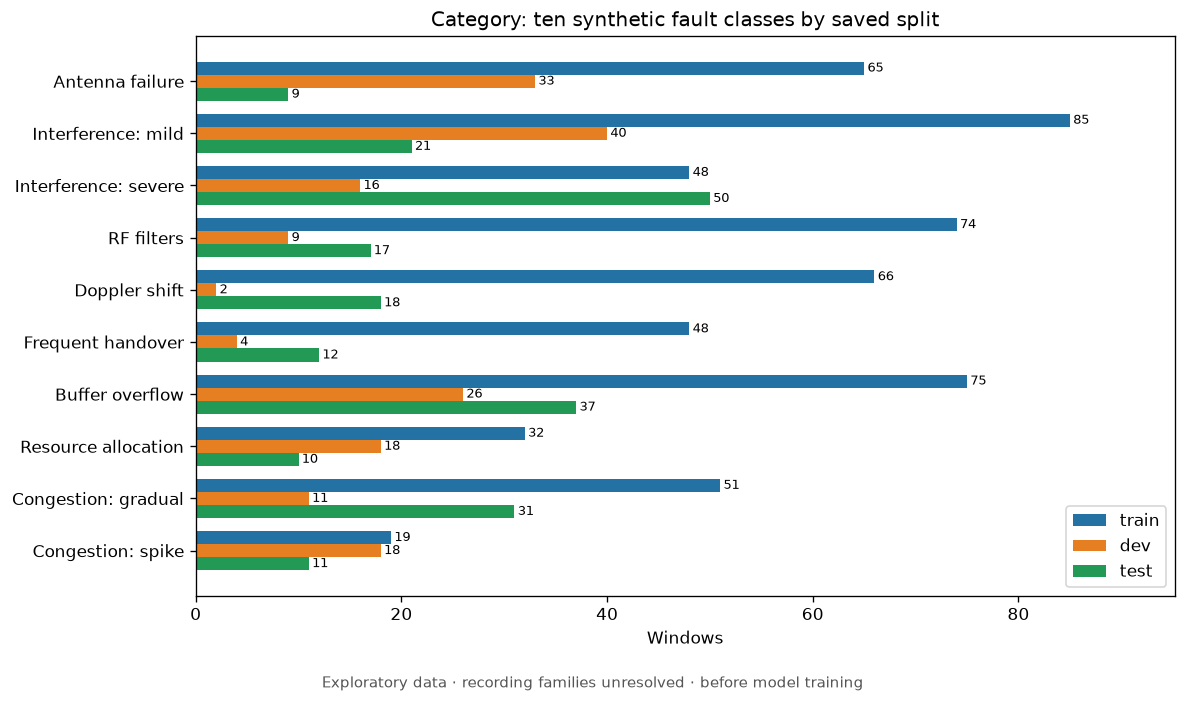

In [4]:
display(Image(filename=str(plots["category_counts.png"])))

## Optional training-window reduction analysis

This plot shows the proposed nonoverlap selection for normal windows while retaining faults. It is a separate data review; the Random Forest result below used every eligible training window and did not apply this selection.

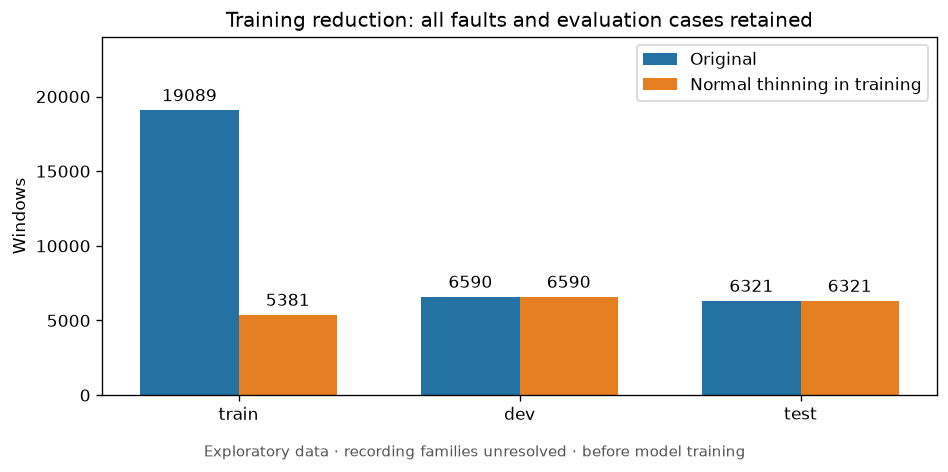

In [5]:
display(Image(filename=str(plots["training_reduction.png"])))

## Representative observations

Each row shows one source window, chosen deterministically by source path and row number. All 128 samples are shown at their original 10 Hz rate. These are illustrations, not class averages.

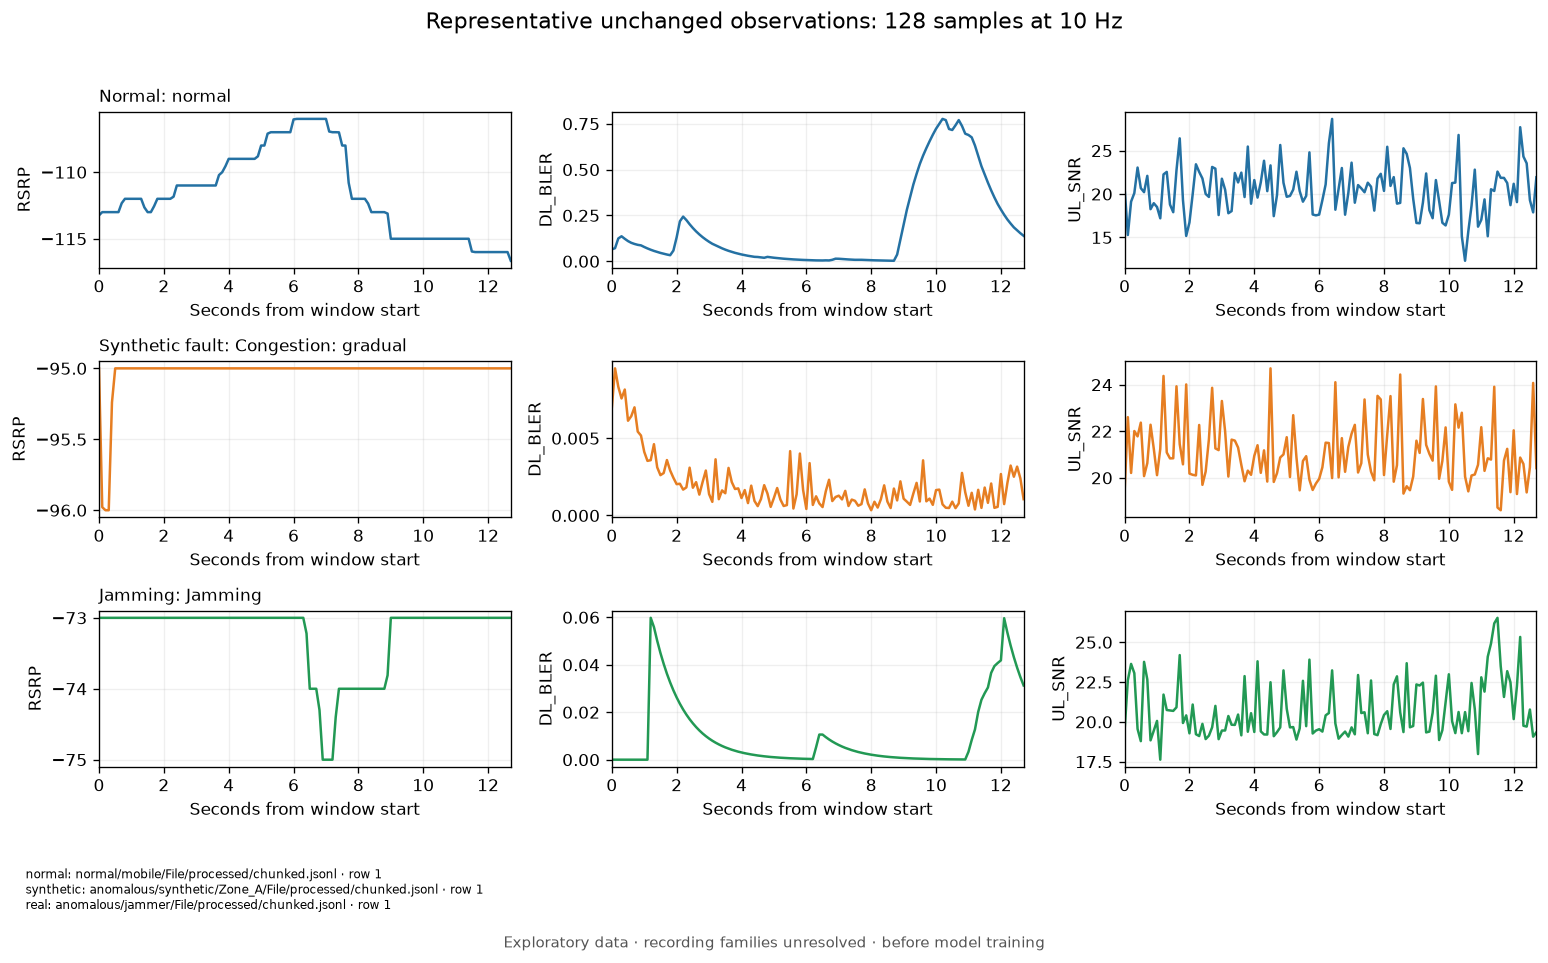

In [6]:
display(Image(filename=str(plots["representative_kpis.png"])))

## Head of the RF training data

Each row below is one training window after the same 224-feature transform used by the detector. The example shows a few features plus the target and source type. Channel medians come from the saved training checkpoint.

In [7]:
from itertools import islice
from clauseguard.baselines.artifacts import load_run
from clauseguard.datasets.scenarios import ScenarioDataset
from clauseguard.kpi.random_forest import load_model

FULL_RUN = DATA_ROOT / "artifacts/experiments/rf-all-data-provisional-2026-10-19"
DETECTION_RUN = FULL_RUN / "detection/config-3-seed-42"
if DETECTION_RUN.exists():
    saved = load_run(DETECTION_RUN)
    detector = load_model(DETECTION_RUN / "model.joblib", expected_sha256=saved["metadata"].checkpoint)
    data = ScenarioDataset(RELEASE, allow_exploratory=True)
    examples = list(islice(data.iter_examples(split="train", task="detection"), 5))
    values = detector.features.transform([example.inputs for example in examples])
    names = detector.features.feature_names_
    shown = ["DL_BLER__mean", "DL_BLER__max", "PRB_Utilization_DL__mean", "RSRP__mean", "UL_SNR__mean"]
    head = pd.DataFrame(values[:, [names.index(name) for name in shown]], columns=shown)
    head.insert(0, "origin", [data.splits["membership"][e.scenario_id]["origin"] for e in examples])
    head.insert(0, "target", [e.target for e in examples])
    head.insert(0, "scenario_id", [e.scenario_id[:18] + "…" for e in examples])
    display(head)
    print(f"Showing 5 of {saved['metadata'].cohort.coverage['train']['windows']:,} training windows; {len(names)} features per window.")
else:
    print("Run the full-data RF training command below to create the checkpoint for this example.")

,scenario_id,target,origin,DL_BLER__mean,DL_BLER__max,PRB_Utilization_DL__mean,RSRP__mean,UL_SNR__mean
0,telecomts-00095e76…,0,normal,0.000070,0.000170,0.005163,-88.000000,21.052031
1,telecomts-000d22a6…,0,normal,0.000008,0.000040,0.007375,-87.184083,21.606016
2,telecomts-000dea30…,0,normal,0.000000,0.000000,2.155812,-112.031252,20.607500
3,telecomts-000f2450…,0,normal,0.000000,0.000000,1.599416,-87.508765,20.740508
4,telecomts-000f68a9…,0,normal,0.137077,0.334055,16.668475,-119.249394,20.098945


Showing 5 of 19,089 training windows; 224 features per window.


## Fixture training demonstration

These small generated inputs test fitting and checkpoint reload for both tasks. They are **not TelecomTS** and their outputs are not experiment scores. The same feature and RF functions are used by the real runner.

In [8]:
import json
import tempfile
import numpy as np
import pandas as pd
from clauseguard.datasets.contracts import NUMERIC_CHANNELS, ModelInputs, NumericInputs
from clauseguard.kpi.random_forest import fit_model, serialize_model, load_model

rng = np.random.default_rng(42)
def fixture_inputs(labels):
    return [ModelInputs(kpi=NumericInputs(
        channel_names=list(NUMERIC_CHANNELS), sampling_rate_hz=10,
        values=rng.normal(float(label), 0.1, size=(128, 16)).tolist(),
    )) for label in labels]

fixture_root = ROOT / "artifacts/experiments/random-forest-notebook-demo"
fixture_root.mkdir(parents=True, exist_ok=True)
fixture_output = Path(tempfile.mkdtemp(prefix="fixture-", dir=fixture_root))
fixture_results = []
for task, classes in (("detection", 2), ("category", 10)):
    labels = np.repeat(np.arange(classes), 8).tolist()
    model = fit_model(fixture_inputs(labels), labels, task=task,
                      configuration={"max_depth": 12, "min_samples_leaf": 1}, seed=42)
    content, checksum = serialize_model(model)
    checkpoint = fixture_output / f"{task}.joblib"
    checkpoint.write_bytes(content)
    loaded = load_model(checkpoint, expected_sha256=checksum)
    probes = fixture_inputs(range(classes))
    assert loaded.predict(probes) == model.predict(probes)
    fixture_results.append({"task": task, "fixture_windows": len(labels),
                            "trees": model.forest.n_estimators, "features": model.forest.n_features_in_,
                            "reload_matches": True, "checkpoint_sha256": checksum})
(fixture_output / "fixture.json").write_text(json.dumps(
    {"data_kind": "generated_fixture", "models": fixture_results}, indent=2) + "\n")
display(pd.DataFrame(fixture_results).drop(columns="checkpoint_sha256"))
print("Fixture checkpoints:", fixture_output)

,task,fixture_windows,trees,features,reload_matches
0,detection,16,300,224,True
1,category,80,300,224,True


Fixture checkpoints: /Users/tanzimfarhan/Desktop/SLU/clauseguard-ran/artifacts/experiments/random-forest-notebook-demo/fixture-mhgqemt4


## Full-data training

The run below uses every eligible training window (`TRAINING_SELECTION = None`), selects settings on dev, and saves the chosen settings for seeds 42/43/44. It uses an explicit exploratory opt-in because recording independence is unresolved. Test remains untouched until the separate prediction step.

In [9]:
from clauseguard.datasets.scenarios import ScenarioDataset
from clauseguard.baselines.random_forest import run_random_forest, predict_saved_model

quality = json.loads((RELEASE / "quality.json").read_text())
COVERAGE_READY = all(quality["tasks"][task]["kpi"]["coverage_ready"] for task in ("detection", "category"))
RECORDING_READY = all(quality["tasks"][task]["kpi"]["ready"] for task in ("detection", "category"))
print("Split coverage for both tasks:", COVERAGE_READY)
print("Recording independence reviewed:", RECORDING_READY)
print("Any result from this release must be labelled provisional.")

RUN_REAL_TRAINING = False  # Set True to rerun the full-data experiment.
TRAINING_SELECTION = None  # None keeps every eligible training window.
TRAIN_OUTPUT = DATA_ROOT / "artifacts/experiments/rf-full-data-new-run"
summary = None
if RUN_REAL_TRAINING:
    if not COVERAGE_READY:
        raise ValueError("The release lacks train/dev/test label coverage.")
    dataset = ScenarioDataset(RELEASE, allow_exploratory=True)
    summary = run_random_forest(
        dataset, TRAIN_OUTPUT, training_selection=TRAINING_SELECTION,
        allow_exploratory=True,
    )
    display(pd.DataFrame([
        {"task": task, "train_windows": row["train_windows"],
         "configuration": row["selected_configuration"],
         "dev_macro_f1_mean": row["dev_macro_f1_mean"],
         "dev_macro_f1_std": row["dev_macro_f1_std"]}
        for task, row in summary["tasks"].items()
    ]))

Split coverage for both tasks: True
Recording independence reviewed: False
Any result from this release must be labelled provisional.


## Full-data result

These are the saved results from the 2026-10-19 run on the full training cohort. Detection separates normal from abnormal. Category predicts one of ten synthetic fault labels. The category test score is weak and based on only two recording groups; it is not a stable estimate.

In [10]:
RESULTS = DATA_ROOT / "artifacts/experiments/rf-all-data-provisional-2026-10-19"
if RESULTS.exists():
    detection = json.loads((RESULTS / "detection/test-seed-42/metrics.json").read_text())
    category = json.loads((RESULTS / "category/test-seed-42/metrics.json").read_text())
    selected = json.loads((RESULTS / "selection.json").read_text())["tasks"]
    display(pd.DataFrame([
        {"task": "detection", "train": selected["detection"]["train_windows"],
         "dev macro-F1, mean ± SD": f"{selected['detection']['dev_macro_f1_mean']:.3f} ± {selected['detection']['dev_macro_f1_std']:.3f}",
         "test macro-F1": detection["macro_f1"], "test accuracy": detection["accuracy"],
         "fault recall": detection["recall"], "false alarms": detection["false_alarms"],
         "missed faults": detection["missed_faults"]},
        {"task": "category", "train": selected["category"]["train_windows"],
         "dev macro-F1, mean ± SD": f"{selected['category']['dev_macro_f1_mean']:.3f} ± {selected['category']['dev_macro_f1_std']:.3f}",
         "test macro-F1": category["macro_f1"], "test accuracy": category["accuracy"],
         "fault recall": None, "false alarms": None, "missed faults": None},
    ]))
    labels = json.loads((RELEASE / "labels.json").read_text())["category"]
    split = json.loads((RELEASE / "splits.json").read_text())["membership"]
    train_support = {}
    for row in split.values():
        if row["split"] == "train" and row["category_target"] is not None:
            train_support[row["category_target"]] = train_support.get(row["category_target"], 0) + 1
    class_rows = []
    for label, score in category["per_class"].items():
        label = int(label)
        class_rows.append({"class": next(name for name, value in labels.items() if value == label),
                           "train": train_support.get(label, 0), "test": score["support"],
                           "precision": score["precision"], "recall": score["recall"], "F1": score["f1"]})
    display(pd.DataFrame(class_rows).sort_values("class").reset_index(drop=True))
    predictions_path = RESULTS / "detection/test-seed-42/predictions.jsonl"
    predictions = {row["scenario_id"]: row["predicted_label"] for row in map(json.loads, predictions_path.open())}
    expected = json.loads((RESULTS / "detection/test-seed-42/targets.json").read_text())["expected"]
    members = json.loads((RELEASE / "splits.json").read_text())["membership"]
    origin_rows = []
    for origin in ("normal", "synthetic", "real"):
        cases = [sid for sid in expected if members[sid]["origin"] == origin]
        faults = [sid for sid in cases if expected[sid] == 1]
        caught = sum(predictions[sid] == 1 for sid in faults)
        false_alarms = sum(expected[sid] == 0 and predictions[sid] == 1 for sid in cases)
        origin_rows.append({"origin": origin, "windows": len(cases), "faults": len(faults),
                            "caught": caught, "missed": len(faults) - caught, "false alarms": false_alarms})
    display(pd.DataFrame(origin_rows))
    print("Category test confidence interval:", category["confidence_intervals"]["reason"])
else:
    print("Saved full-data experiment artifacts are not present in this checkout.")

,task,train,"dev macro-F1, mean ± SD",test macro-F1,test accuracy,fault recall,false alarms,missed faults
0,detection,19089,0.661 ± 0.005,0.663347,0.961240,0.210356,1.0,244.0
1,category,563,0.569 ± 0.025,0.223574,0.310185,NaN,NaN,NaN


,class,train,test,precision,recall,F1
0,Antenna Failure,65,9,0.400000,0.666667,0.500000
1,Buffer Overflow (Gradual Buildup),75,37,0.468750,0.405405,0.434783
2,Co-Channel Interference (Mild),85,21,0.157407,0.809524,0.263566
3,Co-Channel Interference (Severe),48,50,0.681818,0.300000,0.416667
4,Doppler Shift (Severe),66,18,0.235294,0.222222,0.228571
5,Faulty Handover Algorithm (Too Frequent),48,12,0.000000,0.000000,0.000000
6,Faulty RF Filters (Temporal),74,17,0.000000,0.000000,0.000000
7,High Network Congestion (Gradual Buildup),51,31,0.500000,0.322581,0.392157
8,High Network Congestion (Sudden Spike),19,11,0.000000,0.000000,0.000000
9,Resource Allocation Bugs,32,10,0.000000,0.000000,0.000000


,origin,windows,faults,caught,missed,false alarms
0,normal,6012,0,0,0,1
1,synthetic,216,216,63,153,0
2,real,93,93,2,91,0


Category test confidence interval: requires at least 10 recording groups


## Optional reduced-cohort rerun

This diagnostic caps detection train, dev, and test at 3,000 windows each. It keeps every training fault, samples normal training windows by recording group, and samples dev/test by group and label. The category cohorts have only 563/177/216 windows, so they remain complete. Fixed seeds make the sample repeatable.

The test subset is for comparison only. Keep the full test result above as the main score. This release has unresolved recording families, so neither version supports a final performance claim.

In [11]:
RUN_REDUCED_ANALYSIS = False  # Set True to rerun both tasks on the reduced cohorts.
MAX_WINDOWS = 3000
REDUCTION_SEED = 20261019

if RUN_REDUCED_ANALYSIS:
    import numpy as np
    from collections import defaultdict
    from clauseguard.datasets.release import project_inputs
    from clauseguard.datasets.splits import select_task_cohort
    from clauseguard.kpi.features import ChannelMedianFeatures
    from clauseguard.kpi.random_forest import CONFIGURATIONS, fit_forest
    from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, confusion_matrix

    reduced_data = ScenarioDataset(RELEASE, allow_exploratory=True)
    membership = reduced_data.splits["membership"]

    def sample_ids(ids, task, split, limit, seed):
        if len(ids) <= limit:
            return list(ids)
        buckets = defaultdict(list)
        for sid in ids:
            row = membership[sid]
            if task == "detection" and split == "train" and row["detection_target"] == 1:
                continue
            bucket = row["group_id"] if task == "detection" and split == "train" else (row["group_id"], row[f"{task}_target"])
            buckets[bucket].append(sid)
        fixed = [sid for sid in ids if task == "detection" and split == "train" and membership[sid]["detection_target"] == 1]
        budget = limit - len(fixed)
        total = sum(map(len, buckets.values()))
        quotas = {key: max(1, int(budget * len(rows) / total)) for key, rows in buckets.items()}
        while sum(quotas.values()) > budget:
            key = max((k for k in quotas if quotas[k] > 1), key=lambda k: quotas[k] - budget * len(buckets[k]) / total)
            quotas[key] -= 1
        while sum(quotas.values()) < budget:
            key = max((k for k in quotas if quotas[k] < len(buckets[k])), key=lambda k: budget * len(buckets[k]) / total - quotas[k])
            quotas[key] += 1
        rng = np.random.default_rng(seed)
        chosen = fixed[:]
        for key in sorted(buckets, key=str):
            chosen.extend(rng.choice(buckets[key], size=quotas[key], replace=False).tolist())
        return sorted(chosen)

    def load_rows(ids, task):
        rows = [project_inputs(reduced_data.load_scenario(sid), modality="kpi", task=task) for sid in ids]
        labels = [membership[sid][f"{task}_target"] for sid in ids]
        return rows, labels

    reduced_results = []
    for task in ("detection", "category"):
        ids_by_split = {}
        rows_by_split = {}
        labels_by_split = {}
        for split in ("train", "dev", "test"):
            full_ids = select_task_cohort(reduced_data.splits, split=split, task=task, modality="kpi")
            ids = sample_ids(full_ids, task, split, MAX_WINDOWS, REDUCTION_SEED + len(reduced_results) + len(split))
            ids_by_split[split] = ids
            rows_by_split[split], labels_by_split[split] = load_rows(ids, task)
        transformer = ChannelMedianFeatures().fit(rows_by_split["train"])
        x_train = transformer.transform(rows_by_split["train"])
        x_dev = transformer.transform(rows_by_split["dev"])
        x_test = transformer.transform(rows_by_split["test"])
        trials = []
        for configuration in CONFIGURATIONS:
            forest = fit_forest(x_train, labels_by_split["train"], task=task, configuration=configuration, seed=42)
            trials.append((f1_score(labels_by_split["dev"], forest.predict(x_dev), average="macro"), configuration, forest))
        dev_score, configuration, forest = max(trials, key=lambda item: item[0])
        test_pred = forest.predict(x_test)
        result = {"task": task, "train": len(ids_by_split["train"]), "dev": len(ids_by_split["dev"]),
                  "test": len(ids_by_split["test"]), "selected_config": configuration,
                  "dev_macro_f1": dev_score, "test_macro_f1": f1_score(labels_by_split["test"], test_pred, average="macro"),
                  "test_accuracy": accuracy_score(labels_by_split["test"], test_pred)}
        if task == "detection":
            y_dev = np.asarray(labels_by_split["dev"])
            p_dev = forest.predict_proba(x_dev)[:, list(forest.classes_).index(1)]
            candidates = np.unique(np.r_[p_dev, np.nextafter(p_dev.max(), 1.0)])
            eligible = []
            for threshold in candidates:
                pred = (p_dev >= threshold).astype(int)
                tn, fp, fn, tp = confusion_matrix(y_dev, pred, labels=[0, 1]).ravel()
                if fp / (fp + tn) <= 0.05:
                    eligible.append((tp / (tp + fn), threshold))
            _, threshold = max(eligible, key=lambda item: item[0])
            p_test = forest.predict_proba(x_test)[:, list(forest.classes_).index(1)]
            threshold_pred = (p_test >= threshold).astype(int)
            tn, fp, fn, tp = confusion_matrix(labels_by_split["test"], threshold_pred, labels=[0, 1]).ravel()
            result.update({"dev_selected_threshold_fpr_cap": 0.05, "threshold": float(threshold),
                           "test_threshold_recall": recall_score(labels_by_split["test"], threshold_pred),
                           "test_threshold_precision": precision_score(labels_by_split["test"], threshold_pred, zero_division=0),
                           "test_threshold_false_alarms": int(fp), "test_threshold_missed_faults": int(fn)})
        reduced_results.append(result)
    display(pd.DataFrame(reduced_results))
    print(json.dumps(reduced_results, indent=2))

## Held-out prediction

Use a selected checkpoint after settings are fixed. Prediction reloads the saved medians, feature order, and weights; it does not refit them. This release requires explicit exploratory opt-in.

In [14]:
RUN_TEST_PREDICTION = True
MODEL_RUN = DATA_ROOT / "artifacts/experiments/rf-all-data-provisional-2026-10-19/detection/config-3-seed-42"
TEST_OUTPUT = DATA_ROOT / "artifacts/experiments/rf-test-from-notebook-2026-10-19"
if RUN_TEST_PREDICTION:
    test_metrics = predict_saved_model(
        ScenarioDataset(RELEASE, allow_exploratory=True), MODEL_RUN, TEST_OUTPUT,
        allow_exploratory=True,
    )
    display({key: test_metrics[key] for key in ("count", "accuracy", "macro_f1", "recall", "missed_faults")})

{'count': 6321,
 'accuracy': 0.9612403100775194,
 'macro_f1': 0.6633471916524007,
 'recall': 0.21035598705501618,
 'missed_faults': 244}

The same full-data workflow is available from the terminal:

```bash
uv run python -m clauseguard.cli.random_forest train \
  --task both --allow-exploratory \
  --release-dir data/scenarios/release \
  --output-dir artifacts/experiments/rf-full-data-new-run

uv run python -m clauseguard.cli.random_forest predict \
  --allow-exploratory \
  --release-dir data/scenarios/release \
  --model-run-dir artifacts/experiments/rf-full-data-new-run/detection/config-3-seed-42 \
  --output-dir artifacts/experiments/rf-test-new-run --split test
```

The full-run detection accuracy of 96% is misleading because 95% of the test windows are normal. The model catches 65/309 faults and misses 244, including 91/93 jammer windows. Dev and test macro-F1 are close (0.661 and 0.663), so these scores do not show a general train-to-test gap. A dev-selected lower decision threshold is explored in the optional reduced-cohort cell; it is not part of the saved baseline.

Category macro-F1 is 0.224. Review class support and recording groups before tuning against the small test set.